# Organic Farming Suitability Prediction Using Machine Learning

**Student Name:** Nehalata Maji  
**Roll No:** BWU/BCA/24/541  
**Course:** Bachelor of Computer Applications (BCA)  
**Department:** Department of Computational Sciences, Brainware University, Kolkata  
**Project:** Project Based Learning (PBL) - Machine Learning  

---

### Project Overview
The objective of this project is to build a binary classification model that predicts whether a given agricultural field is **Suitable** or **Not Suitable** for organic farming based on soil parameters, weather data, and past fertilizer and pesticide usage.

**Dataset Note:** The dataset consists of 1,000 source-calibrated records based on Soil Health Card parameters. `Suitability_Score` has been excluded from model training to prevent target leakage.

In [1]:
# Import required libraries
import warnings
warnings.filterwarnings("ignore")
import numpy as np
np.seterr(all="ignore")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")

Libraries loaded successfully.


### 1. Data Loading and Basic Inspection

In [2]:
# Load the dataset
data_path = "../data/organic_farming_suitability_1000_source_calibrated.csv"
df = pd.read_csv(data_path)
df.columns = [c.strip() for c in df.columns]

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.head()

Dataset shape: (1000, 24)
Missing values: 0
Duplicates: 0


,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,...,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,...,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,...,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,...,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,...,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable


### 2. Target Variable and Summary Statistics

In [3]:
# Check target class distribution
print("Target Distribution:")
print(df["Organic_Farming_Suitability"].value_counts())
print("\nTarget Percentage:")
print(df["Organic_Farming_Suitability"].value_counts(normalize=True) * 100)

df.describe().T[["mean", "std", "min", "50%", "max"]]

Target Distribution:
Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64

Target Percentage:
Organic_Farming_Suitability
Not Suitable    57.7
Suitable        42.3
Name: proportion, dtype: float64


,mean,std,min,50%,max
pH,6.915940,0.754045,4.800,6.9250,9.190
Organic_Carbon_pct,0.724501,0.346696,0.189,0.6535,2.500
Available_N_kg_ha,259.016700,91.347824,80.000,257.3000,588.100
Available_P_kg_ha,29.549400,16.859065,3.000,29.1000,86.300
Available_K_kg_ha,254.252700,126.799430,40.000,242.3500,653.200
Available_S_mg_kg,15.801290,6.615834,3.000,15.5400,39.060
Available_Zn_mg_kg,0.785150,0.366406,0.150,0.7100,4.000
Available_Fe_mg_kg,20.480830,12.802683,2.990,17.3350,80.000
Available_Mn_mg_kg,9.191230,5.361124,1.440,7.7650,40.000
Available_Cu_mg_kg,0.774470,0.385222,0.170,0.6950,4.000


### 3. Exploratory Data Analysis

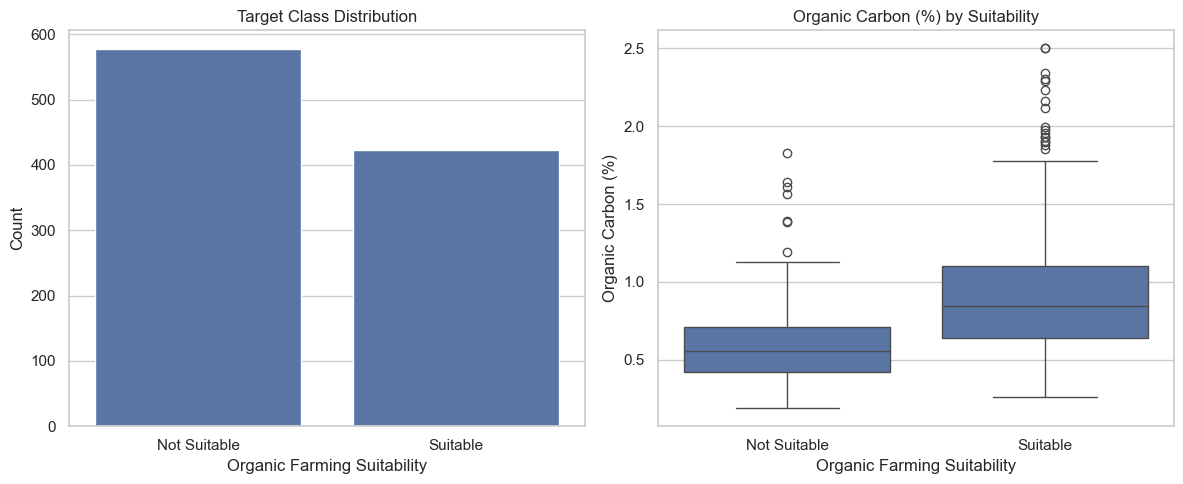

In [4]:
# Plot target distribution and organic carbon
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="Organic_Farming_Suitability", ax=axes[0])
axes[0].set_title("Target Class Distribution")
axes[0].set_xlabel("Organic Farming Suitability")
axes[0].set_ylabel("Count")

sns.boxplot(data=df, x="Organic_Farming_Suitability", y="Organic_Carbon_pct", ax=axes[1])
axes[1].set_title("Organic Carbon (%) by Suitability")
axes[1].set_xlabel("Organic Farming Suitability")
axes[1].set_ylabel("Organic Carbon (%)")

plt.tight_layout()
plt.show()

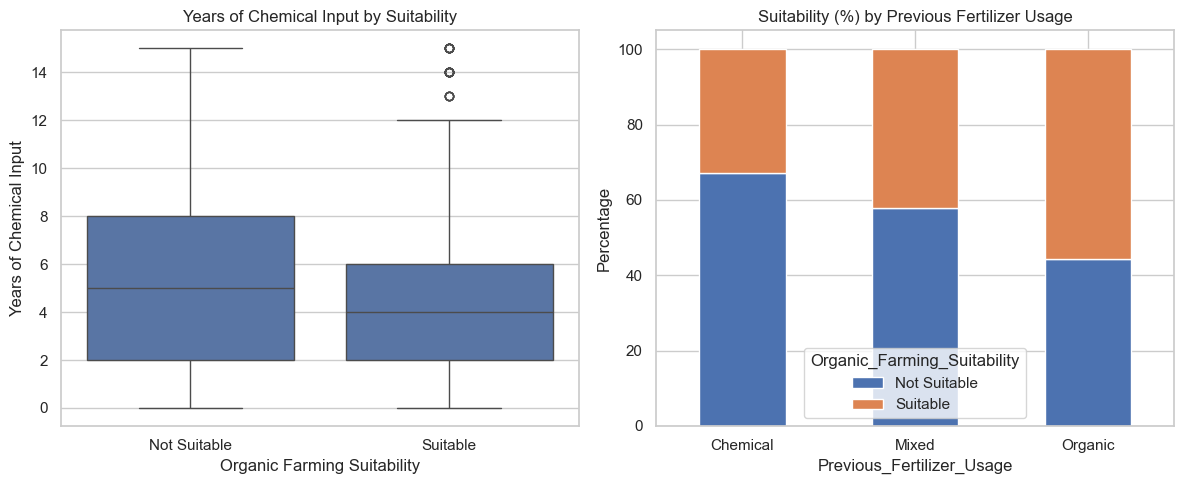

In [5]:
# Plot years of chemical input and previous fertilizer usage
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Organic_Farming_Suitability", y="Years_Chemical_Input", ax=axes[0])
axes[0].set_title("Years of Chemical Input by Suitability")
axes[0].set_xlabel("Organic Farming Suitability")
axes[0].set_ylabel("Years of Chemical Input")

fert_table = pd.crosstab(df["Previous_Fertilizer_Usage"], df["Organic_Farming_Suitability"], normalize="index") * 100
fert_table.plot(kind="bar", stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Suitability (%) by Previous Fertilizer Usage")
axes[1].set_ylabel("Percentage")

plt.tight_layout()
plt.show()

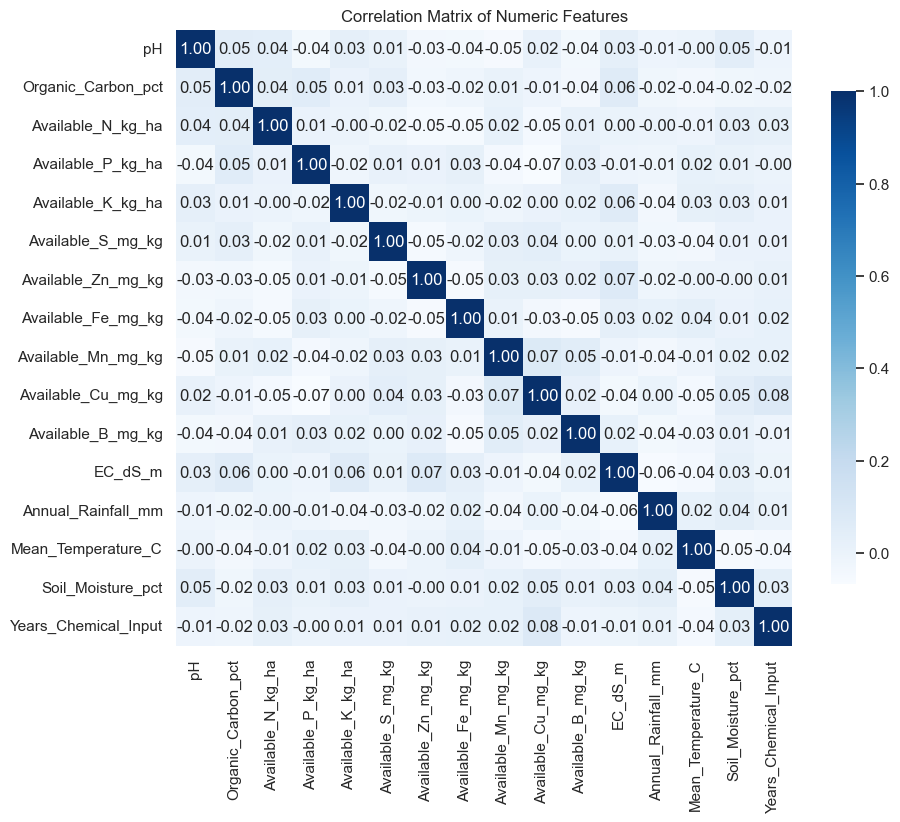

In [6]:
# Correlation heatmap of numeric soil parameters
numeric_features = [
    "pH", "Organic_Carbon_pct", "Available_N_kg_ha", "Available_P_kg_ha", "Available_K_kg_ha",
    "Available_S_mg_kg", "Available_Zn_mg_kg", "Available_Fe_mg_kg", "Available_Mn_mg_kg",
    "Available_Cu_mg_kg", "Available_B_mg_kg", "EC_dS_m", "Annual_Rainfall_mm",
    "Mean_Temperature_C", "Soil_Moisture_pct", "Years_Chemical_Input"
]

plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of Numeric Features")
plt.show()

### 4. Data Preprocessing and Train-Test Split
`Suitability_Score` and `Sample_ID` are dropped from the input features to prevent data leakage.  
The data is split into 80% training and 20% testing sets using stratified sampling.

In [7]:
# Define feature columns and target
categorical_features = ["State", "Soil_Type", "Crop", "Previous_Fertilizer_Usage", "Previous_Pesticide_Usage"]

X = df[numeric_features + categorical_features].copy()
y = df["Organic_Farming_Suitability"].map({"Not Suitable": 0, "Suitable": 1}).astype(int)

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# Build preprocessor
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])
print("Preprocessing pipeline created.")

Training set shape: (800, 21)
Testing set shape: (200, 21)
Preprocessing pipeline created.


### 5. Model Training and Comparison
We compare six classification models using 5-fold stratified cross-validation on the training set, and evaluate performance on the held-out test set.

In [8]:
# Define models to train
import warnings
warnings.filterwarnings("ignore")
import numpy as np
np.seterr(all="ignore")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=0.8, solver="liblinear", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=10, min_samples_leaf=5, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, subsample=0.85, random_state=42),
    "Support Vector Machine": SVC(kernel="rbf", C=1.5, probability=True, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_data = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else y_pred
    
    benchmark_data.append({
        "Model": name,
        "CV_Accuracy": np.mean(cv_scores["test_accuracy"]),
        "CV_F1": np.mean(cv_scores["test_f1"]),
        "Test_Accuracy": accuracy_score(y_test, y_pred),
        "Test_Precision": precision_score(y_test, y_pred, zero_division=0),
        "Test_Recall": recall_score(y_test, y_pred, zero_division=0),
        "Test_F1_Score": f1_score(y_test, y_pred, zero_division=0),
        "Test_ROC_AUC": roc_auc_score(y_test, y_prob)
    })

results_table = pd.DataFrame(benchmark_data).sort_values(by="Test_F1_Score", ascending=False).reset_index(drop=True)
results_table.round(4)

,Model,CV_Accuracy,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score,Test_ROC_AUC
0,Gradient Boosting,0.8488,0.8118,0.830,0.8000,0.8000,0.8000,0.9003
1,Logistic Regression,0.8362,0.8002,0.805,0.7875,0.7412,0.7636,0.8899
2,Support Vector Machine,0.8337,0.7973,0.795,0.7821,0.7176,0.7485,0.8978
3,Random Forest,0.8237,0.7671,0.770,0.7532,0.6824,0.7160,0.8767
4,K-Nearest Neighbors,0.7625,0.7105,0.770,0.7600,0.6706,0.7125,0.8362
5,Decision Tree,0.7500,0.7031,0.720,0.6593,0.7059,0.6818,0.7863


### 6. Confusion Matrices

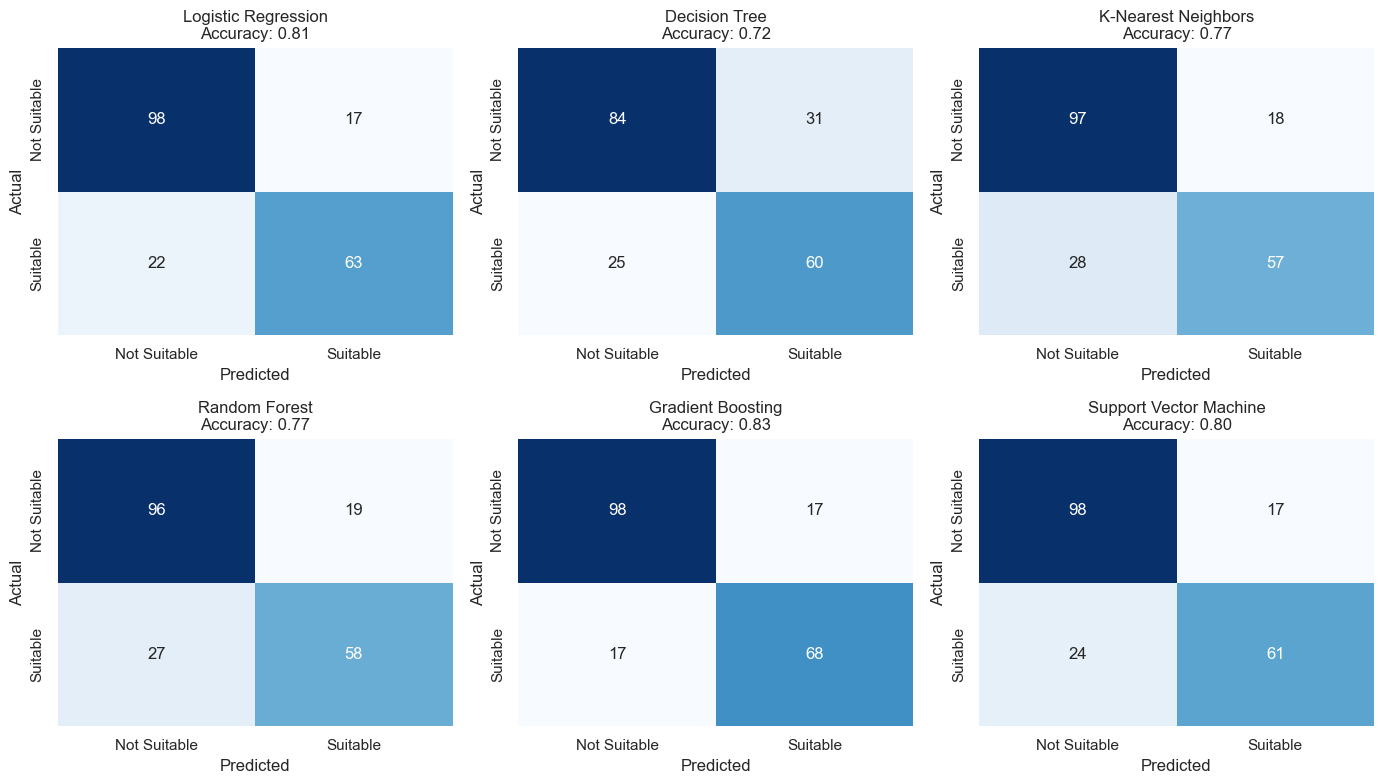

In [9]:
# Plot confusion matrix for all models
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for idx, (name, pipe) in enumerate(trained_pipelines.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    acc = results_table.loc[results_table["Model"] == name, "Test_Accuracy"].values[0]
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Not Suitable", "Suitable"], yticklabels=["Not Suitable", "Suitable"])
    axes[idx].set_title(f"{name}\nAccuracy: {acc:.2f}")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### 7. ROC Curves

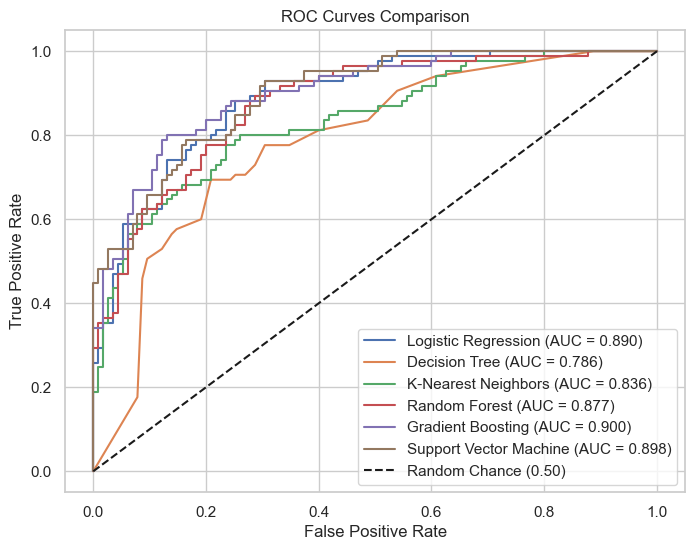

In [10]:
# Plot ROC curves
plt.figure(figsize=(8, 6))

for name, pipe in trained_pipelines.items():
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Chance (0.50)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison")
plt.legend(loc="lower right")
plt.show()

### 8. Feature Importance Analysis

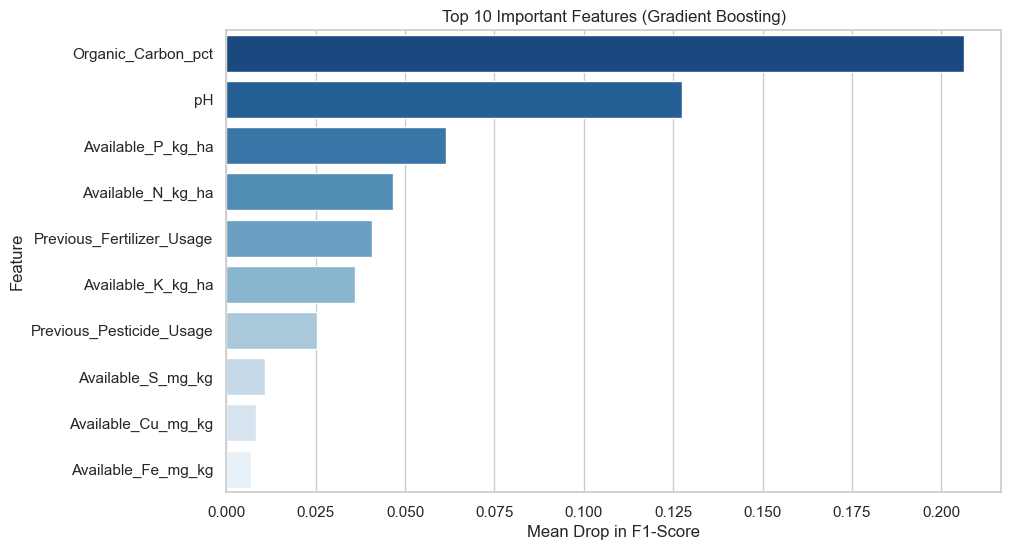

In [11]:
# Calculate permutation feature importance on test set
best_model_name = results_table.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]

perm_res = permutation_importance(best_pipe, X_test, y_test, n_repeats=10, random_state=42, scoring="f1")

feat_imp = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_res.importances_mean
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", palette="Blues_r")
plt.title(f"Top 10 Important Features ({best_model_name})")
plt.xlabel("Mean Drop in F1-Score")
plt.ylabel("Feature")
plt.show()

### 9. Save Best Model

In [12]:
# Save the best performing pipeline
model_save_path = "../models/best_organic_farming_pipeline.joblib"
joblib.dump(best_pipe, model_save_path)
print(f"Model saved successfully to {model_save_path}")

Model saved successfully to ../models/best_organic_farming_pipeline.joblib
